# RKHS Outlier Detection: Mini Tutorial

This notebook demonstrates the effectiveness of the filtering pipeline based on Reproducing Kernel Hilbert Spaces (RKHS). 

Rather than using arbitrary sequence identity cutoffs, this model uses **Rademacher concentration inequalities** to mathematically determine which sequences diverge abnormally from the center of mass of a protein family.

### In this tutorial:
1. **Loading** a multiple sequence alignment (FASTA).
2. **Vectorized computation** of the kernel matrix (via NumPy).
3. **Classification** of sequences (normal vs. outliers).
4. Interactive **MDS visualization** of the similarity space.

*Make sure you have installed the dependencies via `pip` before running the cells.*

In [1]:
# To have access to the src folder/files
import sys, os
sys.path.append(os.path.abspath('..'))

import matplotlib.pyplot as plt
from src.parser import read_fasta
from src.detector import OutlierClassifier
from sklearn.manifold import MDS

/home/charlie/exteme-protein-detection-rkhs/.venv/lib/python3.14/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/home/charlie/exteme-protein-detection-rkhs/.venv/lib/python3.14/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


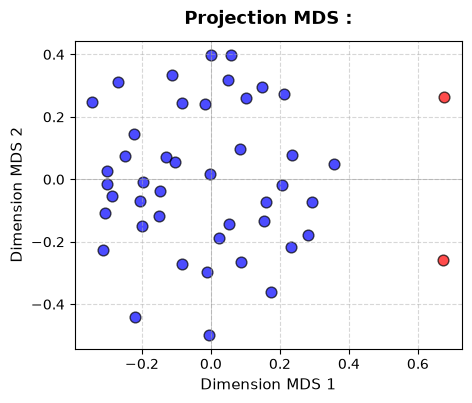

In [4]:
# Create the distance matrix of the alignment example
names, sequences = read_fasta("../example/BB20017.fasta")

classifier = OutlierClassifier(sequences, names, kernel="poly", gamma=0.8)

df_results = classifier.fit_predict(delta=0.1)

# Distance matrix
D = 1.0 - classifier._K
        
# MDS
mds = MDS(n_components=2, dissimilarity="precomputed", random_state=42, n_init=4)
coordonnees_2d = mds.fit_transform(D)
plt.figure(figsize=(5,4))

normals = coordonnees_2d[~df_results['is_outlier']]
outliers = coordonnees_2d[df_results['is_outlier']]

# Plot
plt.scatter(
    normals[:,0], 
    normals[:,1], 
    color="blue", 
    alpha=0.7, 
    edgecolors="black", 
    s=60)

plt.scatter(
    outliers[:,0], 
    outliers[:,1], 
    color="red", 
    alpha=0.7, 
    edgecolors="black", 
    s=60)

plt.title(f"Projection MDS :", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Dimension MDS 1", fontsize=11)
plt.ylabel("Dimension MDS 2", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
        
plt.axhline(0, color="grey", linewidth=0.5, alpha=0.5)
plt.axvline(0, color="grey", linewidth=0.5, alpha=0.5)
plt.show()

The extreme proteins have been found, marked in red in this MDS representation.

---